# Grid-search based co-design optimization

```
rsync -avm --include='*/' --include='*.sql*' --exclude='*' jhummel@snellius.surf.nl:/home/jhummel/Tower-clearance-co-design/data/co-design/ ./data/co-design/ --dry-run
```

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.interpolate import griddata
from weis.visualization.utils import load_OMsql, load_OMsql_multi

plt.style.use("journal.mplstyle")

# %matplotlib widget

pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.DeprecationWarning: /home/jhummel/miniforge3/envs/tip_clearance/lib/python3.13/site-packages/pkg_resources/__init__.py:3146
Deprecated call to `pkg_resources.declare_namespace('sphinxcontrib')`.
Implementing implicit namespace packages (as specified in PEP 420) is preferred to `pkg_resources.declare_namespace`. See https://setuptools.pypa.io/en/latest/references/keywords.html#keyword-namespace-packagesDeprecationWarning: /home/jhummel/miniforge3/envs/tip_clearance/lib/python3.13/site-packages/jsonmerge/__init__.py:27
Accessing Draft4Validator.resolver is deprecated as of v4.18.0, in favor of the https://github.com/python-jsonschema/referencing library, which provides more compliant referencing behavior as well as more flexible APIs for customization.PendingDepre

In [2]:
logs_to_load = {
    "Baseline": "../../../data/co-design/baseline_28823409/baseline_slim.sql",
    "Free yaw": "../../../data/co-design/free_yaw_28869679/free_yaw_slim.sql",
}

# Load all datasets.
all_data_dicts = {}
for log_name, log_fmt in logs_to_load.items():
    all_data_dicts[log_name] = load_OMsql(log_fmt)
    print(f"Loaded {log_name}: {all_data_dicts[log_name].keys()}")

Loaded Baseline: dict_keys(['aeroelastic.platform_displacement', 'aeroelastic.hub_system_cm', 'aeroelastic.platform_elem_rho', 'aeroelastic.platform_elem_E', 'aeroelastic.platform_elem_G', 'aeroelastic.platform_total_center_of_mass', 'aeroelastic.platform_mass', 'aeroelastic.platform_I_total', 'aeroelastic.beta_wave', 'aeroelastic.gamma_f', 'aeroelastic.gamma_m', 'aeroelastic.E', 'aeroelastic.twr2shaft', 'aeroelastic.Xt', 'aeroelastic.Xc', 'aeroelastic.m', 'aeroelastic.definition_layer', 'aeroelastic.sc_ss_mats', 'aeroelastic.sc_ps_mats', 'aeroelastic.te_ss_mats', 'aeroelastic.te_ps_mats', 'aeroelastic.monopile_wohlerexp', 'aeroelastic.monopile_wohlerA', 'aeroelastic.monopile_ultstress', 'aeroelastic.pitch_axis', 'aeroelastic.monopile_axial_load2stress', 'aeroelastic.monopile_shear_load2stress', 'aeroelastic.transition_node', 'aeroelastic.platform_nodes', 'aeroelastic.platform_elem_n1', 'aeroelastic.platform_elem_n2', 'aeroelastic.platform_elem_D', 'aeroelastic.platform_elem_t', 'aeroe

In [3]:
# Let's define how we load, scale, and label the data, then make a dataframe.
all_outputs = {
    # Did the run have a failure.
    "openfast_failed": {
        "key": "aeroelastic.openfast_failed",
        "scaling": lambda x: x[0],
        "label": "Openfast failed",
    },
    # ROSCO variables.
    "TCIPC_MaxTipDeflection": {
        "key": "tune_rosco_ivc.TCIPC_MaxTipDeflection",
        "scaling": lambda x: x[0],
        "label": "TCIPC deflection reference (m)",
    },
    "ps_percent": {
        "key": "tune_rosco_ivc.ps_percent",
        "scaling": lambda x: x[0],
        "label": "Peak shaving (-)",
    },
    "max_thrust_percent": {
        "key": "tune_rosco_ivc.ps_percent",
        "scaling": lambda x: 100 * x[0],
        "label": "Max thrust (%)",
    },
    "TCIPC_nHarmonics": {
        "key": "tune_rosco_ivc.TCIPC_nHarmonics",
        "scaling": lambda x: x[0],
        "label": "Number of harmonics",
    },
    "TCIPC_ZeroYawDeflection": {
        "key": "tune_rosco_ivc.TCIPC_ZeroYawDeflection",
        "scaling": lambda x: x[0],
        "label": "Zero yaw deflection",
    },
    "TCIPC_MaxPitchAmplitude": {
        "key": "tune_rosco_ivc.TCIPC_MaxPitchAmplitude",
        "scaling": lambda x: np.round(np.rad2deg(x[0]), 1),
        "label": "TCIPC max pitch amplitude (deg)",
    },
    # Design variables
    "cone": {
        "key": "hub.cone",
        "scaling": lambda x: np.rad2deg(x[0]),
        "label": "Cone angle (deg)",
    },
    "tilt": {
        "key": "nacelle.uptilt",
        "scaling": lambda x: np.rad2deg(x[0]),
        "label": "Tilt angle (deg)",
    },
    "overhang": {
        "key": "nacelle.overhang",
        "scaling": lambda x: x[0],
        "label": "Overhang (m)",
    },
    # Objective.
    "aep": {
        "key": "aeroelastic.AEP",
        "scaling": lambda x: 1e-6 * x[0],
        "label": "AEP (GWh)",
    },
    # Constraints.
    "max_eff_TipDxc_towerPassing": {
        "key": "aeroelastic.max_eff_TipDxc_towerPassing",
        "scaling": lambda x: x[0],
        "label": "max_eff_TipDxc_towerPassing",
    },
    "tower_clearance": {
        "key": "aeroelastic.minimum_tower_clearance",
        "scaling": lambda x: x[0],
        "label": "Tower clearance (m)",
    },
    "eff_tower_clearance": {
        "key": "aeroelastic.minimum_eff_tower_clearance",
        "scaling": lambda x: x[0],
        "label": "Tower clearance (m)",
    },
    "eff_tower_clearance_DLC": {
        "key": "aeroelastic.minimum_eff_tower_clearance_DLC",
        "scaling": lambda x: x[0],
        "label": "Tower clearance (m)",
    },
    "eff_tower_clearance_URef": {
        "key": "aeroelastic.minimum_eff_tower_clearance_URef",
        "scaling": lambda x: x[0],
        "label": "Tower clearance (m)",
    },
    # Structural loads.
    "max_eff_TwrBsMyt": {
        "key": "aeroelastic.max_eff_TwrBsMyt",
        "scaling": lambda x: x[0] / 1000,
        "label": "Tower ultimate (MNm)",
    },
    "max_eff_TwrBsMyt_DLC": {
        "key": "aeroelastic.max_eff_TwrBsMyt_DLC",
        "scaling": lambda x: str(x[0]),
        "label": "Max tower base Myt DLC (-)",
    },
    "max_eff_TwrBsMyt_URef": {
        "key": "aeroelastic.max_eff_TwrBsMyt_URef",
        "scaling": lambda x: x[0],
        "label": "Max tower base Myt U (m/s)",
    },
    "DEL_TwrBsMyt": {
        "key": "aeroelastic.DEL_TwrBsMyt",
        "scaling": lambda x: x[0] / 1000,
        "label": "Tower fatigue (MNm)",
    },
    "max_eff_RootMyb": {
        "key": "aeroelastic.max_eff_RootMyb",
        "scaling": lambda x: x[0] / 1000,
        "label": "Blade ultimate (MNm)",
    },
    "max_eff_RootMyb_DLC": {
        "key": "aeroelastic.max_eff_RootMyb_DLC",
        "scaling": lambda x: str(x[0]),
        "label": "Max root Myb DLC (-)",
    },
    "max_eff_RootMyb_URef": {
        "key": "aeroelastic.max_eff_RootMyb_URef",
        "scaling": lambda x: x[0],
        "label": "Max root Myb U (m/s)",
    },
    "DEL_RootMyb": {
        "key": "aeroelastic.DEL_RootMyb",
        "scaling": lambda x: x[0] / 1000,
        "label": "Blade fatigue (MNm)",
    },
    # Control activity.
    "max_pitch_rate_sim": {
        "key": "aeroelastic.max_pitch_rate_sim",
        "scaling": lambda x: x[0],
        "label": "Max pitch rate (deg/s)",
    },
    "max_pitch_rate_sim_DLC": {
        "key": "aeroelastic.max_pitch_rate_sim_DLC",
        "scaling": lambda x: str(x[0]),
        "label": "Max pitch rate DLC (-)",
    },
    "max_pitch_rate_sim_URef": {
        "key": "aeroelastic.max_pitch_rate_sim_U",
        "scaling": lambda x: x[0],
        "label": "Max pitch rate U (m/s)",
    },
    "avg_pitch_travel": {
        "key": "aeroelastic.avg_pitch_travel",
        "scaling": lambda x: x[0],
        "label": "Avg pitch travel (deg)",
    },
}

# Build dataframe from mapping for each log.
labels = {short: info["label"] for short, info in all_outputs.items()}
all_dfs = []

for log_name, data_dict in all_data_dicts.items():
    df_dict = {}
    for short_label, info in all_outputs.items():
        data = data_dict[info["key"]]
        scaled_data = list(map(info["scaling"], data))
        df_dict[short_label] = scaled_data

    df_temp = pd.DataFrame(df_dict)
    df_temp["log_name"] = log_name
    all_dfs.append(df_temp)

# Combine all dataframes.
df = pd.concat(all_dfs, ignore_index=True)
print(f"Combined dataframe shape: {df.shape}")
with pd.option_context(
    "display.max_rows",
    20,
    "display.max_columns",
    None,
    "display.precision",
    3,
):
    display(df)

Combined dataframe shape: (750, 29)


,openfast_failed,TCIPC_MaxTipDeflection,ps_percent,max_thrust_percent,TCIPC_nHarmonics,TCIPC_ZeroYawDeflection,TCIPC_MaxPitchAmplitude,cone,tilt,overhang,aep,max_eff_TipDxc_towerPassing,tower_clearance,eff_tower_clearance,eff_tower_clearance_DLC,eff_tower_clearance_URef,max_eff_TwrBsMyt,max_eff_TwrBsMyt_DLC,max_eff_TwrBsMyt_URef,DEL_TwrBsMyt,max_eff_RootMyb,max_eff_RootMyb_DLC,max_eff_RootMyb_URef,DEL_RootMyb,max_pitch_rate_sim,max_pitch_rate_sim_DLC,max_pitch_rate_sim_URef,avg_pitch_travel,log_name
0,2.0,0.0,0.6,60.0,1.0,0.0,0.0,0.0,0.0,12.031,53.027,9.078,0.000,0.000,1.1,9.00,364.245,1.4,10.59,34.165,103.471,1.4,10.59,15.420,0.071,1.4,10.59,0.057,Baseline
1,0.0,0.0,0.6,60.0,1.0,0.0,0.0,5.0,0.0,12.031,76.784,16.224,5.542,6.327,1.4,10.59,370.123,1.4,10.59,48.083,105.162,1.4,10.59,21.644,0.108,1.3,10.59,0.066,Baseline
2,0.0,0.0,0.6,60.0,1.0,0.0,0.0,10.0,0.0,12.031,77.608,18.785,13.463,14.458,1.4,10.59,387.072,1.4,10.59,48.293,108.950,1.4,10.59,22.387,0.115,1.3,10.59,0.068,Baseline
3,0.0,0.0,0.6,60.0,1.0,0.0,0.0,15.0,0.0,12.031,80.431,23.885,19.932,20.388,1.4,10.59,405.364,1.4,10.59,49.710,115.138,1.4,10.59,24.525,0.107,1.3,10.59,0.077,Baseline
4,0.0,0.0,0.6,60.0,1.0,0.0,0.0,20.0,0.0,12.031,80.772,28.340,27.282,27.614,1.4,10.59,427.945,1.4,10.59,51.151,123.416,1.4,10.59,27.072,0.119,1.3,10.59,0.084,Baseline
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
745,0.0,25.0,1.0,100.0,2.0,0.0,4.0,0.0,20.0,12.031,78.819,18.322,34.341,35.393,1.5,10.59,355.448,1.4,10.59,45.644,96.889,1.4,10.59,20.689,0.101,1.3,10.59,0.088,Free yaw
746,0.0,25.0,1.0,100.0,2.0,0.0,4.0,5.0,20.0,12.031,79.862,20.015,43.164,44.042,1.5,10.59,329.078,1.4,10.59,46.295,97.374,1.4,10.59,21.986,0.110,1.3,10.59,0.089,Free yaw
747,0.0,25.0,1.0,100.0,2.0,0.0,4.0,10.0,20.0,12.031,80.572,22.268,51.847,52.453,1.5,10.59,353.773,1.4,10.59,47.117,107.072,1.4,10.59,23.906,0.126,1.4,10.59,0.092,Free yaw
748,0.0,25.0,1.0,100.0,2.0,0.0,4.0,15.0,20.0,12.031,81.009,25.221,59.023,60.695,1.4,10.59,395.344,1.4,10.59,48.567,116.051,1.4,10.59,25.837,0.145,1.4,10.59,0.098,Free yaw


In [4]:
df.groupby(["openfast_failed", "log_name"]).count()

TCIPC_MaxTipDeflection  ps_percent  \
openfast_failed log_name                                       
0.0             Baseline                     120         120   
                Free yaw                     610         610   
2.0             Baseline                       5           5   
                Free yaw                      15          15   

                          max_thrust_percent  TCIPC_nHarmonics  \
openfast_failed log_name                                         
0.0             Baseline                 120               120   
                Free yaw                 610               610   
2.0             Baseline                   5                 5   
                Free yaw                  15                15   

                          TCIPC_ZeroYawDeflection  TCIPC_MaxPitchAmplitude  \
openfast_failed log_name                                                     
0.0             Baseline                      120                      120   
                Free yaw                      610                      610   
2.0             Baseline                        5                        5   
                Free yaw                       15                       15   

                          cone  tilt  overhang  aep  ...  \
openfast_failed log_name                             ...   
0.0             Baseline   120   120       120  120  ...   
                Free yaw   610   610       610  610  ...   
2.0             Baseline     5     5         5    5  ...   
                Free yaw    15    15        15   15  ...   

                          max_eff_TwrBsMyt_URef  DEL_TwrBsMyt  \
openfast_failed log_name                                        
0.0             Baseline                    120           120   
                Free yaw                    610           610   
2.0             Baseline                      5             5   
                Free yaw                     15            15   

                          max_eff_RootMyb  max_eff_RootMyb_DLC  \
openfast_failed log_name                                         
0.0             Baseline              120                  120   
                Free yaw              610                  610   
2.0             Baseline                5                    5   
                Free yaw               15                   15   

                          max_eff_RootMyb_URef  DEL_RootMyb  \
openfast_failed log_name                                      
0.0             Baseline                   120          120   
                Free yaw                   610          610   
2.0             Baseline                     5            5   
                Free yaw                    15           15   

                          max_pitch_rate_sim  max_pitch_rate_sim_DLC  \
openfast_failed log_name                                               
0.0             Baseline                 120                     120   
                Free yaw                 610                     610   
2.0             Baseline                   5                       5   
                Free yaw                  15                      15   

                          max_pitch_rate_sim_URef  avg_pitch_travel  
openfast_failed log_name                                             
0.0             Baseline                      120               120  
                Free yaw                      610               610  
2.0             Baseline                        5                 5  
                Free yaw                       15                15  

[4 rows x 27 columns]

In [5]:
# Give the baseline the same design space as Free yaw: copy every baseline row
# once for each TCIPC_MaxTipDeflection value present in the Free yaw data.
tcipc_maxtipdeflection_values = np.sort(
    df.loc[df["log_name"] == "Free yaw", "TCIPC_MaxTipDeflection"].unique()
)
print(f"TCIPC_MaxTipDeflection values: {tcipc_maxtipdeflection_values}")

is_baseline = df["log_name"] == "Baseline"
df_baseline = df[is_baseline]
df_baseline_ext = pd.concat(
    [
        df_baseline.assign(TCIPC_MaxTipDeflection=v)
        for v in tcipc_maxtipdeflection_values
    ],
    ignore_index=True,
)

df = pd.concat([df[~is_baseline], df_baseline_ext], ignore_index=True)
print(df.groupby("log_name").size())  # Expect 625 for both.

TCIPC_MaxTipDeflection values: [ 0.    6.25 12.5  18.75 25.  ]
log_name
Baseline    625
Free yaw    625
dtype: int64


# Data exploration

In [6]:
objectives = ["eff_tower_clearance", "aep"]
design_variables = ["cone", "tilt", "max_thrust_percent", "TCIPC_MaxTipDeflection"]
constraints = [
    "openfast_failed",
    "max_eff_RootMyb",
    "max_eff_TwrBsMyt",
    "DEL_RootMyb",
    "DEL_TwrBsMyt",
]
constraint_values = {
    "openfast_failed": 1,
    "max_eff_RootMyb": 106791.238828125 / 1e3,
    "max_eff_TwrBsMyt": 363545.1221875 / 1e3,
    "DEL_RootMyb": 22115.983753505523 / 1e3,
    "DEL_TwrBsMyt": 49976.581934041016 / 1e3,
}
# We can do a simple constraint satisfaction calculation. Note that this assumes that
# all constraints are maximum constraints (which they are).
df["constraint_satisfaction"] = sum(
    np.maximum(df[c] / cv - 1, 0) for c, cv in constraint_values.items()
)
df["constraint_satisfied"] = df["constraint_satisfaction"] == 0

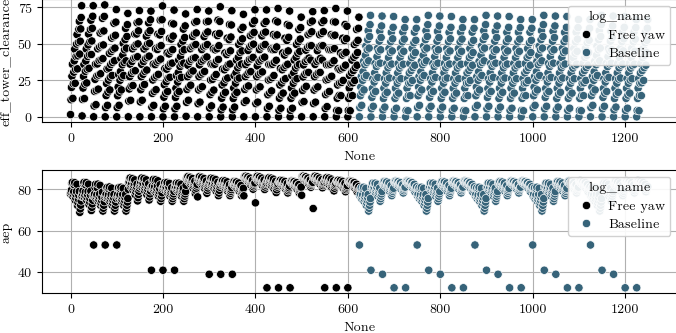

In [7]:
fig, axs = plt.subplots(len(objectives))

for i, objective in enumerate(objectives):
    sns.scatterplot(df, x=df.index, y=objective, hue="log_name", ax=axs[i])

<Axes: xlabel='None', ylabel='constraint_satisfaction'>

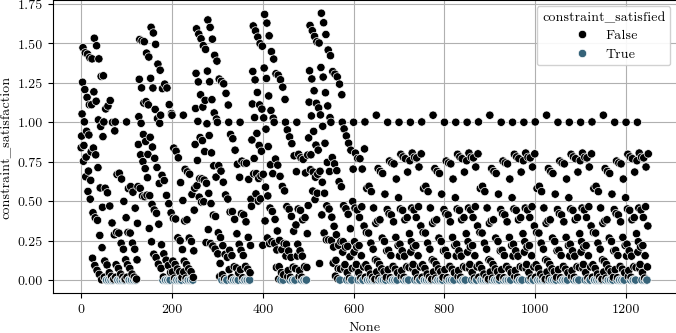

In [8]:
# Constraint satisfaction
sns.scatterplot(
    data=df,
    x=df.index,
    y="constraint_satisfaction",
    hue="constraint_satisfied",
)

<Axes: xlabel='eff_tower_clearance', ylabel='aep'>

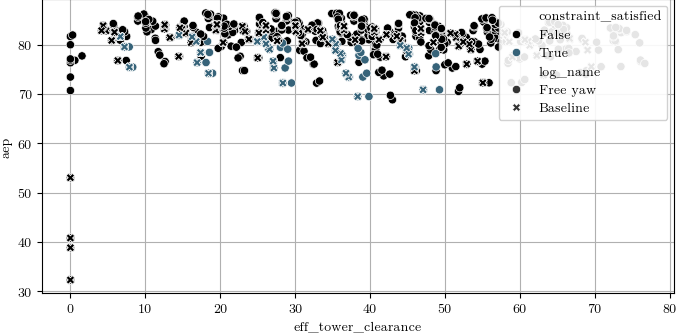

In [9]:
# Objectives.
sns.scatterplot(
    data=df,
    x=objectives[0],
    y=objectives[1],
    hue="constraint_satisfied",
    style="log_name",
)

<Axes: xlabel='cone', ylabel='tilt'>

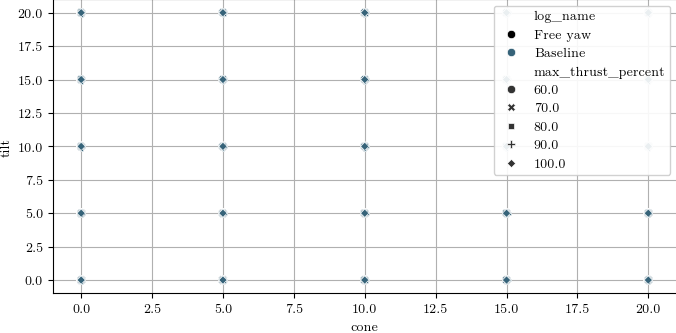

In [10]:
# Design variables.
sns.scatterplot(
    data=df,
    x=design_variables[0],
    y=design_variables[1],
    style=design_variables[2],
    hue="log_name",
)

<Axes: xlabel='eff_tower_clearance', ylabel='aep'>

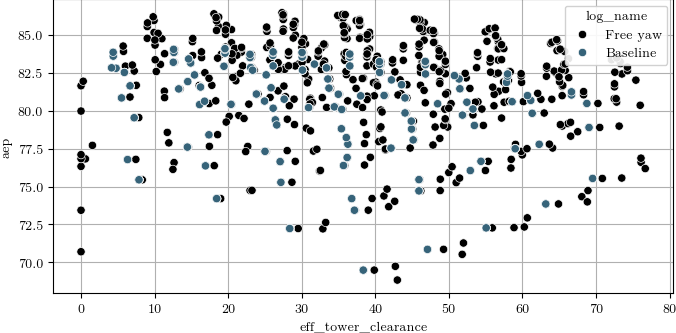

In [30]:
sns.scatterplot(
    data=df[df["openfast_failed"] < 1], x="eff_tower_clearance", y="aep", hue="log_name"
)

# Data interpolation

In [16]:
from scipy.interpolate import (
    CloughTocher2DInterpolator,
    LinearNDInterpolator,
    RBFInterpolator,
)

In [17]:
class InterpolatorSet:
    """Builds interpolators for all numeric columns of a dataframe subset.

    Given a dataframe (typically filtered to one log_name), this creates a
    scipy interpolator for each numeric column, using the specified design
    variable columns as inputs. Works for any number of dimensions.
    """

    def __init__(self, df, design_vars, method="linear"):
        xy = df[list(design_vars)].values
        self._ndim = len(design_vars)

        if method == "cubic" and self._ndim > 2:
            # CloughTocher only works for 2D; use RBF for higher dimensions.
            self._interpolators = {}
            for col in df.select_dtypes(include=[np.number]).columns:
                if col in design_vars:
                    continue
                rbf = RBFInterpolator(xy, df[col].values, kernel="thin_plate_spline")
                self._interpolators[col] = self._wrap_rbf(rbf)
        else:
            Interpolator = (
                CloughTocher2DInterpolator
                if method == "cubic"
                else LinearNDInterpolator
            )
            self._interpolators = {}
            for col in df.select_dtypes(include=[np.number]).columns:
                if col in design_vars:
                    continue
                self._interpolators[col] = Interpolator(
                    xy, df[col].values, fill_value=0.0
                )

    @staticmethod
    def _wrap_rbf(rbf):
        """Wrap RBFInterpolator to accept *args like LinearNDInterpolator."""

        def wrapper(*args):
            xi = np.column_stack([np.atleast_1d(a) for a in args])
            result = rbf(xi)
            return result[0] if result.size == 1 else result

        return wrapper

    def __getitem__(self, column):
        return self._interpolators[column]

In [18]:
# Let's see what reasonable bounds for the design variables are.
df["eff_tower_clearance_below_35"] = df["eff_tower_clearance"] < 35
df[df["constraint_satisfied"]].groupby(["eff_tower_clearance_below_35", "log_name"])[
    design_variables
].agg(["min", "max"])

cone       tilt        \
                                       min  max   min   max   
eff_tower_clearance_below_35 log_name                         
False                        Baseline  0.0  5.0  15.0  20.0   
                             Free yaw  0.0  5.0  15.0  20.0   
True                         Baseline  0.0  5.0   5.0  15.0   
                             Free yaw  0.0  5.0   5.0  15.0   

                                      max_thrust_percent         \
                                                     min    max   
eff_tower_clearance_below_35 log_name                             
False                        Baseline               60.0  100.0   
                             Free yaw               60.0  100.0   
True                         Baseline               60.0  100.0   
                             Free yaw               60.0  100.0   

                                      TCIPC_MaxTipDeflection        
                                                         min   max  
eff_tower_clearance_below_35 log_name                               
False                        Baseline                    0.0  25.0  
                             Free yaw                   12.5  25.0  
True                         Baseline                    0.0  25.0  
                             Free yaw                   12.5  25.0

In [39]:
interpolators = {}
log_names = df["log_name"].unique()
for log_name in log_names:
    df_temp = df[(df["openfast_failed"] < 1) & (df["log_name"] == log_name)]
    interpolators[log_name] = InterpolatorSet(
        df_temp,
        design_variables,
        method="linear",
    )

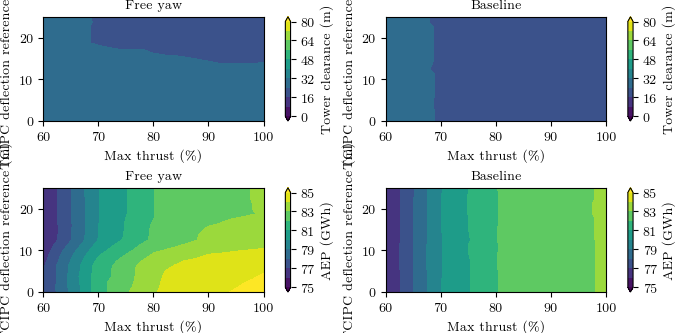

In [65]:
# Objectives.
N = 21

fig, axs = plt.subplots(len(objectives), len(log_names))

zlims = [[0, 80], [75, 85]]

for i, objective in enumerate(objectives):
    for j, log_name in enumerate(log_names):
        x_var, y_var = "max_thrust_percent", "TCIPC_MaxTipDeflection"
        x_range, y_range = (60, 100), (0, 25)
        fixed = {
            "cone": 6,
            "tilt": 8,
            "max_thrust_percent": 90,
            "TCIPC_MaxTipDeflection": 20,
        }

        x_grid, y_grid = np.meshgrid(np.linspace(*x_range, N), np.linspace(*y_range, N))
        coordinates = [
            x_grid
            if var == x_var
            else y_grid
            if var == y_var
            else np.full_like(x_grid, fixed[var])
            for var in design_variables
        ]

        values = interpolators[log_name][objective](*coordinates)
        axs[i, j].set(xlabel=labels[x_var], ylabel=labels[y_var], title=log_name)
        contour = axs[i, j].contourf(
            x_grid,
            y_grid,
            values,
            levels=np.linspace(*zlims[i], 11),
            extend="both",
        )

        fig.colorbar(
            contour,
            ax=axs[i, j],
            label=labels[objective],
            ticks=np.linspace(*zlims[i], 6),
        )


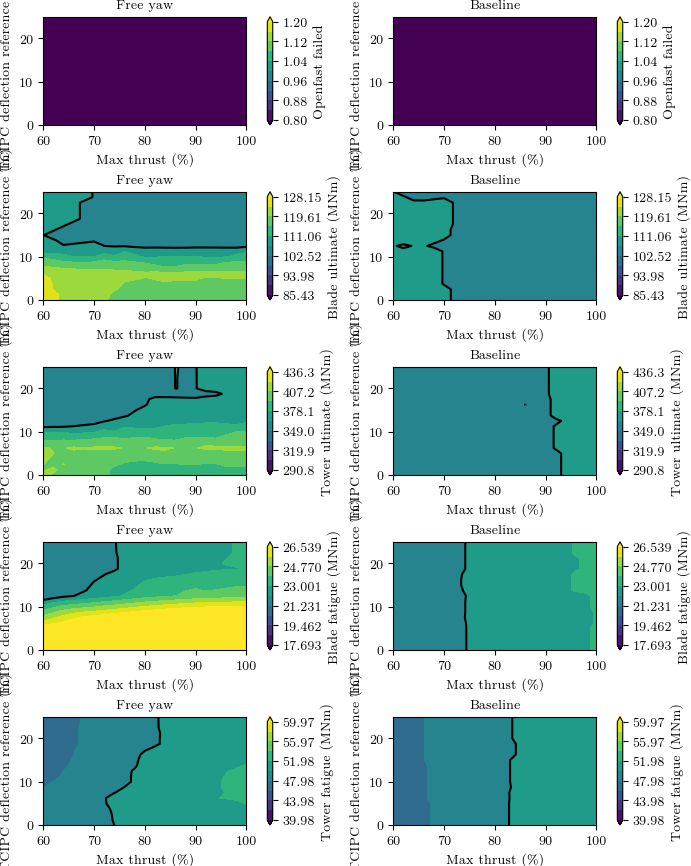

In [66]:
# Objectives.
N = 21

fig, axs = plt.subplots(
    len(constraints), len(log_names), figsize=(7, len(constraints) * 1.75)
)

zlims = [[v * 0.8, v * 1.2] for v in constraint_values.values()]

for i, constraint in enumerate(constraints):
    for j, log_name in enumerate(log_names):
        x_var, y_var = "max_thrust_percent", "TCIPC_MaxTipDeflection"
        x_range, y_range = (60, 100), (0, 25)
        fixed = {
            "cone": 6,
            "tilt": 8,
            "max_thrust_percent": 90,
            "TCIPC_MaxTipDeflection": 20,
        }

        x_grid, y_grid = np.meshgrid(np.linspace(*x_range, N), np.linspace(*y_range, N))
        coordinates = [
            x_grid
            if var == x_var
            else y_grid
            if var == y_var
            else np.full_like(x_grid, fixed[var])
            for var in design_variables
        ]

        values = interpolators[log_name][constraint](*coordinates)
        axs[i, j].set(xlabel=labels[x_var], ylabel=labels[y_var], title=log_name)
        contour = axs[i, j].contourf(
            x_grid,
            y_grid,
            values,
            levels=np.linspace(*zlims[i], 11),
            extend="both",
        )
        contour_ref = axs[i, j].contour(
            x_grid,
            y_grid,
            values,
            levels=[constraint_values[constraint]],
            colors="k",
        )

        fig.colorbar(
            contour,
            ax=axs[i, j],
            label=labels[constraint],
            ticks=np.linspace(*zlims[i], 6),
        )


# Optimization

In [16]:
from pymoo.core.problem import ElementwiseProblem
from pymoo.algorithms.moo.nsga2 import NSGA2
from pymoo.algorithms.moo.nsga3 import NSGA3
from pymoo.algorithms.moo.unsga3 import UNSGA3
from pymoo.algorithms.moo.moead import MOEAD
from pymoo.algorithms.moo.ctaea import CTAEA
from pymoo.algorithms.moo.sms import SMSEMOA
from pymoo.operators.crossover.sbx import SBX
from pymoo.operators.mutation.pm import PM
from pymoo.operators.sampling.rnd import FloatRandomSampling
from pymoo.util.ref_dirs import get_reference_directions
from pymoo.termination import get_termination
from pymoo.optimize import minimize
from pymoo.indicators.hv import Hypervolume
from copy import deepcopy
from itertools import cycle

In [17]:
class OptimizationProblem:
    """Declarative specification of a multi-objective optimization problem.

    Objectives are specified as dicts:
        {"variable": str, "direction": "minimize" | "maximize", "label": str}

    Constraints are specified as dicts:
        {
            "name": str,
            "variable": str,
            "label": str,
            "threshold": float,
            "direction": "below" | "above"
        }
    """

    def __init__(self, objectives, constraints, xl, xu):
        self.objectives = objectives
        self.constraints = constraints
        self.xl = np.array(xl)
        self.xu = np.array(xu)

    def to_pymoo(self, interp_set):
        """Build a pymoo ElementwiseProblem from this specification.

        Pymoo always minimizes, so objectives with direction="maximize" are
        negated internally. Works for any number of design variables.
        """
        objectives = self.objectives
        constraints = self.constraints
        xl = self.xl
        xu = self.xu
        n_var = len(xl)

        # Negate "maximize" objectives so pymoo can minimize them all.
        obj_callables = []
        for obj in objectives:
            interp = interp_set[obj["variable"]]
            sign = -1.0 if obj["direction"] == "maximize" else 1.0
            obj_callables.append(lambda x, _i=interp, _s=sign: _s * _i(*x))

        # Build constraint callables (G <= 0 is feasible).
        con_callables = []
        for con in constraints:
            interp = interp_set[con["variable"]]
            threshold = con["threshold"]
            if con["direction"] == "below":
                con_callables.append(lambda x, _i=interp, _t=threshold: _i(*x) - _t)
            else:
                con_callables.append(lambda x, _i=interp, _t=threshold: _t - _i(*x))

        class _Problem(ElementwiseProblem):
            def __init__(self):
                super().__init__(
                    n_var=n_var,
                    n_obj=len(objectives),
                    n_ieq_constr=len(constraints),
                    xl=xl,
                    xu=xu,
                )

            def _evaluate(self, x, out, *args, **kwargs):
                out["F"] = [f(x) for f in obj_callables]
                out["G"] = [g(x) for g in con_callables]

        return _Problem()

In [18]:
class OptimizationStudy:
    """Runs multi-objective optimization across datasets and algorithms.

    Uses InterpolatorSets to evaluate a surrogate-based optimization problem
    for each log_name in the dataframe. Results are returned as DataFrames
    suitable for plotting with seaborn.
    """

    def __init__(
        self,
        df,
        problem,
        algorithms,
        termination,
        design_vars,
        interp_method="linear",
        seed=1,
        verbose=False,
    ):
        self.df = df
        self.problem = problem
        self.algorithms = algorithms
        self.termination = termination
        self.design_vars = design_vars
        self.interp_method = interp_method
        self.seed = seed
        self.verbose = verbose

        self.log_names = sorted(list(dict.fromkeys(df["log_name"])))
        self.results = {}
        self.interp_sets = {}

    def run(self):
        """Run all optimizations for each (log_name, algorithm) pair."""
        for log_name in self.log_names:
            print(f"Making the interpolation set for {log_name}.")
            df_log = self.df[self.df["log_name"] == log_name]

            self.interp_sets[log_name] = InterpolatorSet(
                df_log, self.design_vars, method=self.interp_method
            )

        for log_name in self.log_names:
            interp_set = self.interp_sets[log_name]
            for algo_name, algo_factory in self.algorithms.items():
                print(f"Starting optimization for {log_name} with {algo_name}.")
                result = minimize(
                    self.problem.to_pymoo(interp_set),
                    deepcopy(algo_factory),
                    deepcopy(self.termination),
                    seed=self.seed,
                    save_history=True,
                    verbose=self.verbose,
                )
                self.results[(log_name, algo_name)] = result
                if result.F is None:
                    print("Didn't get any results...")
                else:
                    print(f"  Done: {log_name} -> {len(result.F)} solutions")

    def _calculate_hv_history(self, result, ref_point=None):
        """Compute hypervolume at each generation from a pymoo result."""
        hist_F = []
        for algo in result.history:
            opt = algo.opt
            feas = np.where(opt.get("feasible"))[0]
            hist_F.append(opt.get("F")[feas])

        if ref_point is not None:
            signs = np.array(
                [
                    -1.0 if o["direction"] == "maximize" else 1.0
                    for o in self.problem.objectives
                ]
            )
            pymoo_ref = np.array(ref_point) * signs
        else:
            pymoo_ref = result.F.max(axis=0)

        metric = Hypervolume(
            ref_point=pymoo_ref,
            norm_ref_point=False,
            zero_to_one=False,
        )
        return [metric.do(_F) for _F in hist_F]

    def convergence_to_dataframe(self, ref_point=None, normalize=False):
        """Return hypervolume convergence history as a DataFrame.

        Each row is one generation for one (log_name, algorithm) pair.
        """
        rows = []
        for (log_name, algo_name), result in self.results.items():
            hv = np.array(self._calculate_hv_history(result, ref_point=ref_point))
            if normalize:
                hv_min, hv_max = hv[0], hv[-1]
                if hv_max > hv_min:
                    hv = (hv - hv_min) / (hv_max - hv_min)
            for gen, h in enumerate(hv):
                rows.append(
                    {
                        "log_name": log_name,
                        "algo_name": algo_name,
                        "generation": gen,
                        "hypervolume": h,
                    }
                )
        return pd.DataFrame(rows)

    def to_dataframe(self):
        """Return all Pareto-optimal solutions as a seaborn-friendly DataFrame.

        Each row is one Pareto-optimal solution. Columns include the design
        variables, objective values (in original space, not pymoo-negated),
        constraint actual values, and all other interpolated outputs.
        """
        signs = np.array(
            [
                -1.0 if o["direction"] == "maximize" else 1.0
                for o in self.problem.objectives
            ]
        )

        rows = []
        for (log_name, algo_name), result in self.results.items():
            interp_set = self.interp_sets[log_name]
            for i in range(len(result.X)):
                x = result.X[i]
                row = {
                    "log_name": log_name,
                    "algo_name": algo_name,
                }

                # Design variables.
                for j, dv in enumerate(self.design_vars):
                    row[dv] = x[j]

                # Objectives in the original space.
                F_original = result.F[i] * signs
                for j, obj in enumerate(self.problem.objectives):
                    row[obj["variable"]] = F_original[j]

                # Constraint actual values.
                for j, con in enumerate(self.problem.constraints):
                    if con["direction"] == "below":
                        row[con["variable"]] = result.G[i, j] + con["threshold"]
                    else:
                        row[con["variable"]] = con["threshold"] - result.G[i, j]

                # All other interpolated output variables.
                for col in interp_set._interpolators:
                    if col not in row:
                        row[col] = float(interp_set[col](*x))

                rows.append(row)

        return pd.DataFrame(rows)

In [19]:
problem = OptimizationProblem(
    objectives=[
        {
            "variable": "eff_tower_clearance",
            "direction": "maximize",
            "label": "Tower clearance (m)",
        },
        {
            "variable": "aep",
            "direction": "maximize",
            "label": "AEP (GWh)",
        },
    ],
    constraints=[
        {
            "name": "Max tower base Myt",
            "variable": "max_eff_TwrBsMyt",
            "label": "Max tower base Myt (MNm)",
            "threshold": constraint_values["max_eff_TwrBsMyt"] * 1.02,
            "direction": "below",
        },
        {
            "name": "Max root Myb",
            "variable": "max_eff_RootMyb",
            "label": "Max root Myb (MNm)",
            "threshold": constraint_values["max_eff_RootMyb"] * 1.02,
            "direction": "below",
        },
        {
            "name": "DEL tower base Myt",
            "variable": "DEL_TwrBsMyt",
            "label": "DEL tower base Myt (MNm)",
            "threshold": constraint_values["DEL_TwrBsMyt"] * 1.0,
            "direction": "below",
        },
        {
            "name": "DEL root Myb",
            "variable": "DEL_RootMyb",
            "label": "DEL root Myb (MNm)",
            "threshold": constraint_values["DEL_RootMyb"] * 1.00,
            "direction": "below",
        },
    ],
    xl=df[design_variables].min().tolist(),
    xu=df[design_variables].max().tolist(),
)

# Specify the algorithms to compare.
ref_dirs = get_reference_directions("uniform", 2, n_partitions=99)

algorithms = {
    "NSGA2": NSGA2(pop_size=200),
}

termination = get_termination("n_gen", 50)

# Run the study across all datasets and algorithms.
study = OptimizationStudy(
    df[df["openfast_failed"] < 1],
    problem=problem,
    algorithms=algorithms,
    termination=termination,
    design_vars=design_variables,
    interp_method="cubic",
)
study.run()

Making the interpolation set for Baseline.
Making the interpolation set for Free yaw.
Starting optimization for Baseline with NSGA2.
  Done: Baseline -> 200 solutions
Starting optimization for Free yaw with NSGA2.
  Done: Free yaw -> 200 solutions


The ``feasible`` property for ``pymoo.core.individual.Individual`` is deprecatedDeprecationWarning: /home/jhummel/miniforge3/envs/tip_clearance/lib/python3.13/site-packages/pymoo/core/individual.py:492
The ``feasible`` property for ``pymoo.core.individual.Individual`` is deprecated

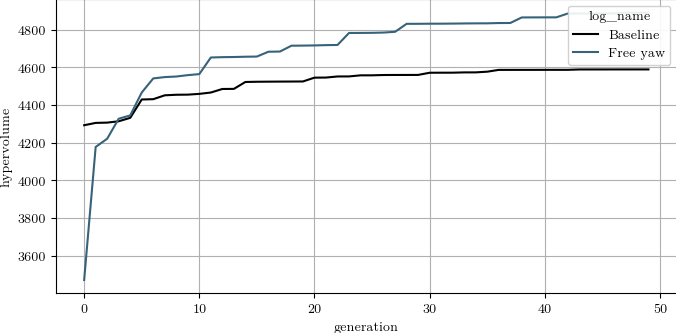

In [20]:
# Hypervolume convergence comparison across all runs.
df_conv = study.convergence_to_dataframe(ref_point=(0, 0), normalize=False)

fig, ax = plt.subplots()
sns.lineplot(data=df_conv, x="generation", y="hypervolume", hue="log_name", ax=ax)
plt.show()

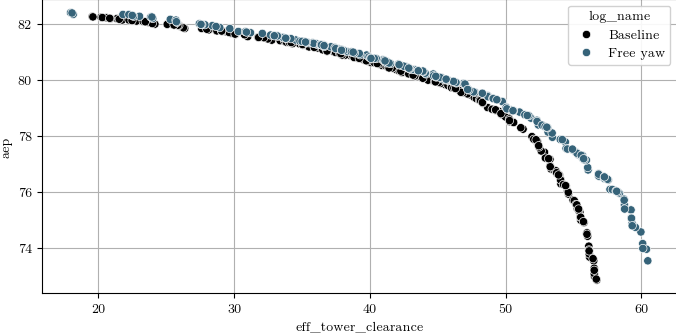

In [21]:
# Pareto front comparison across all runs.
df_pareto = study.to_dataframe()

fig, ax = plt.subplots()
sns.scatterplot(data=df_pareto, y="aep", x="eff_tower_clearance", hue="log_name", ax=ax)
# plt.xlim((15, 25))
# plt.ylim((81, 83))
plt.show()

In [22]:
# Let's see what reasonable bounds for the design variables are.
df_pareto["eff_tower_clearance_below_35"] = df_pareto["eff_tower_clearance"] < 35
df_pareto.groupby("eff_tower_clearance_below_35")[design_variables].agg(
    ["min", "max", "mean"]
)

cone                            tilt  \
                                   min        max      mean        min   
eff_tower_clearance_below_35                                             
False                         4.922362  11.670925  7.549003  14.716348   
True                          1.899690   5.262804  3.885151   9.556347   

                                                   max_thrust_percent  \
                                    max       mean                min   
eff_tower_clearance_below_35                                            
False                         19.999901  18.862769          60.605408   
True                          14.914716  12.334522          89.185653   

                                                   TCIPC_MaxTipDeflection  \
                                    max       mean                    min   
eff_tower_clearance_below_35                                                
False                         98.332467  82.203851               0.875750   
True                          97.395969  93.307096               0.791476   

                                                    
                                    max       mean  
eff_tower_clearance_below_35                        
False                         24.851326  13.979270  
True                          24.432701  14.664406